In [1]:
pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import mysql.connector

In [11]:
conn=mysql.connector.connect(
    host="localhost",
    user="root",
    password="12345678",
    database="Ecommerce"
)
df_tables=pd.read_sql("show tables",conn)
print(df_tables)
print("mysql connected")
print("mysql version:",conn.get_server_info())

  Tables_in_ecommerce
0           customers
1         order_items
2              orders
3            products
mysql connected
mysql version: 8.0.42


C:\Users\hp\AppData\Local\Temp\ipykernel_33632\1127667908.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_tables=pd.read_sql("show tables",conn)
C:\Users\hp\AppData\Local\Temp\ipykernel_33632\1127667908.py:10: DeprecationWarning: Call to deprecated function get_server_info. Reason: 
    The property counterpart 'server_info' should be used instead.

  print("mysql version:",conn.get_server_info())


In [12]:
print(pd.read_sql("describe customers",conn)),
print(pd.read_sql("describe products",conn)),
print(pd.read_sql("describe orders",conn)),
print(pd.read_sql("describe order_items",conn))

           Field         Type Null  Key Default Extra
0    customer_id          int   NO  PRI    None      
1  customer_name  varchar(50)  YES         None      
2           city  varchar(50)  YES         None      
          Field         Type Null  Key Default Extra
0    product_id          int   NO  PRI    None      
1  product_name  varchar(50)  YES         None      
2      category  varchar(50)  YES         None      
3         price          int  YES         None      
         Field  Type Null  Key Default Extra
0     order_id   int   NO  PRI    None      
1  customer_id   int  YES  MUL    None      
2   order_date  date  YES         None      
        Field Type Null  Key Default Extra
0     item_id  int   NO  PRI    None      
1    order_id  int  YES  MUL    None      
2  product_id  int  YES  MUL    None      
3    quantity  int  YES         None      


C:\Users\hp\AppData\Local\Temp\ipykernel_33632\934112591.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql("describe customers",conn)),
C:\Users\hp\AppData\Local\Temp\ipykernel_33632\934112591.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql("describe products",conn)),
C:\Users\hp\AppData\Local\Temp\ipykernel_33632\934112591.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print(pd.read_sql("describe orders",conn)),
C:\Users\hp\AppData\Local\Temp\ipykernel_33632\934112591.py:4: Us

In [17]:
query="""select c.customer_name, c.city, p.product_name, p.category, p.price, oi.quantity, o.order_date, (p.price * oi.quantity) as total_sales
from customers c
join orders o on c.customer_id=o.customer_id
join order_items oi on o.order_id=oi.order_id
join products p on oi.product_id=p.product_id"""
df=pd.read_sql_query(query,conn)
print(df)
print(df.shape)
print("Total revenue")
df["total_sales"].sum()

  customer_name    city product_name     category  price  quantity  \
0         Rahul   Delhi       Laptop  Electronics  50000         1   
1         Priya  Mumbai       Mobile  Electronics  20000         2   
2         Vikas   Patna       Mobile  Electronics  20000         1   
3          Aman  Jaipur      T-shirt      Fashion    999         3   
4         Sneha   Delhi        Shoes      Fashion   1999         1   

   order_date  total_sales  
0  2026-01-05        50000  
1  2026-01-06        40000  
2  2026-03-01        20000  
3  2026-02-10         2997  
4  2026-02-15         1999  
(5, 8)
Total revenue


C:\Users\hp\AppData\Local\Temp\ipykernel_33632\2167190015.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql_query(query,conn)


np.int64(114996)

In [18]:
print("Category_wise:")
print(df.groupby('category')
     ['total_sales'].sum())


print("\nCity_wise:")
print(df.groupby('city')
     ['total_sales'].sum())


print("\nTotal:",
     df['total_sales'].sum())

Category_wise:
category
Electronics    110000
Fashion          4996
Name: total_sales, dtype: int64

City_wise:
city
Delhi     51999
Jaipur     2997
Mumbai    40000
Patna     20000
Name: total_sales, dtype: int64

Total: 114996


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# graph 1 category

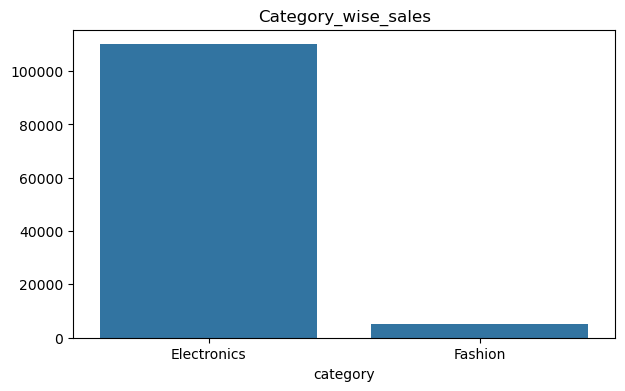

In [21]:
plt.figure(figsize=(7,4))
sns.barplot(x=df.groupby('category')['total_sales'].sum().index,
           y=df.groupby('category')
           ['total_sales'].sum().values)
plt.title('Category_wise_sales')
plt.show()

# Graph 2 City

C:\Users\hp\AppData\Local\Temp\ipykernel_33632\3543755715.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df.groupby('city')


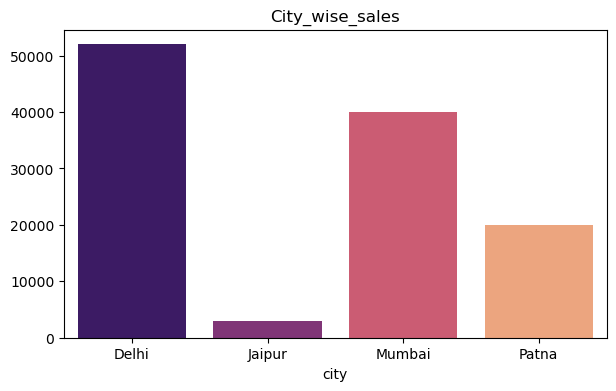

In [27]:
plt.figure(figsize=(7,4))
sns.barplot(x=df.groupby('city')
                     ['total_sales'].sum().index,
                     y=df.groupby('city')
                     ['total_sales'].sum().values,
                     palette='magma')
plt.title('City_wise_sales')
plt.show()
          